# Лабораторна робота № 12
## Рекурентні нейронні мережі (RNN, LSTM). Генерація тексту та підбір гіперпараметрів

**ПІБ студента:** Харченко Артьом Олександрович  
**Група:** ФІТ 3-10  
**Дата:** 27.11.2026

### Мета роботи
Ознайомитися з принципами обробки текстових послідовностей за допомогою **SimpleRNN** та **LSTM**, навчитися підготовлювати текстові дані, будувати й навчати модель передбачення наступного слова, генерувати текст і підбирати гіперпараметри за допомогою **Keras Tuner**.

### Очікуваний результат
- Побудована й навчена модель `Embedding → SimpleRNN → LSTM → Dropout → Dense`.
- Графіки втрат і точності, приклад згенерованого тексту.
- Результат автоматичного підбору гіперпараметрів і порівняння двох моделей.

**Інструкція:** виконуйте кроки послідовно, заповнюйте порожні комірки Python власним кодом. Не видаляйте результати запуску — вони потрібні для перевірки. Рекомендоване середовище: Google Colab або Jupyter Notebook з TensorFlow.

## Частина 1. Створення моделі для передбачення наступного слова

### 1. Імпорт бібліотек
Імпортуйте:
- `numpy` як `np`, `matplotlib.pyplot` як `plt`;
- `Sequential` із `tensorflow.keras.models`;
- `Dense`, `SimpleRNN`, `LSTM`, `Embedding`, `Dropout`;
- `Tokenizer` із `tensorflow.keras.preprocessing.text`;
- `to_categorical` із `tensorflow.keras.utils`.

**Завдання:** переконайтеся, що всі бібліотеки імпортуються без помилок.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, SimpleRNN, LSTM, Embedding, Dropout
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.utils import to_categorical

# щоб результати були більш-менш однакові між запусками
tf.keras.utils.set_random_seed(42)
print("Бібліотеки імпортовано, TensorFlow:", tf.__version__)

Бібліотеки імпортовано, TensorFlow: 2.21.0


### 2. Вхідний текст для навчання
Створіть рядкову змінну `texts` із наведеним фрагментом вірша. Саме цей текст використовується у вихідному прикладі лабораторної роботи.

```text
Думи мої, думи мої,
Лихо мені з вами!
Нащо стали на папері
Сумними рядами?..

Чом вас вітер не розвіяв
В степу, як пилину?
Чом вас лихо не приспало,
Як свою дитину?..

Бо вас лихо на світ на сміх породило,
Поливали сльози... чом не затопили,
Не винесли в море, не розмили в полі?..
```

**Завдання:** виведіть початковий текст або перші 100 його символів.

In [2]:
texts = """Думи мої, думи мої,
Лихо мені з вами!
Нащо стали на папері
Сумними рядами?..

Чом вас вітер не розвіяв
В степу, як пилину?
Чом вас лихо не приспало,
Як свою дитину?..

Бо вас лихо на світ на сміх породило,
Поливали сльози... чом не затопили,
Не винесли в море, не розмили в полі?.."""

print("Довжина тексту:", len(texts), "символів")
print(texts[:100])

Довжина тексту: 281 символів
Думи мої, думи мої,
Лихо мені з вами!
Нащо стали на папері
Сумними рядами?..

Чом вас вітер не розві


### 3. Попередня обробка та токенізація
1. Видаліть із `texts` можливий символ `\ufeff`.
2. Задайте `maxWordsCount = 1000`.
3. Створіть `Tokenizer` із такими налаштуваннями: `num_words=maxWordsCount`, `lower=True`, `split=' '`, `char_level=False`. Для `filters` використайте набір знаків пунктуації з вихідного прикладу, зокрема `!`, `?`, `.`, `,`, тире та лапки.
4. Навчіть токенізатор на тексті за допомогою `fit_on_texts()`.
5. Виведіть кількість знайдених унікальних слів та кілька відповідностей зі словника `word_index`.

**Підказка:** метод `fit_on_texts()` будує словник відповідностей слів і числових індексів.

In [3]:
# прибираємо можливий символ BOM
texts = texts.replace("﻿", "")

maxWordsCount = 1000

tokenizer = Tokenizer(
    num_words=maxWordsCount,
    filters='!–"—#$%&()*+,-./:;<=>?@[\\]^_`{|}~\t\n\r«»',
    lower=True,
    split=' ',
    char_level=False,
)
tokenizer.fit_on_texts([texts])

print("Унікальних слів:", len(tokenizer.word_index))
print("Перші 10 слів зі словника word_index:")
for word, index in list(tokenizer.word_index.items())[:10]:
    print("  ", index, "-", word)

Унікальних слів: 35
Перші 10 слів зі словника word_index:
   1 - не
   2 - лихо
   3 - на
   4 - чом
   5 - вас
   6 - в
   7 - думи
   8 - мої
   9 - як
   10 - мені


### 4. Формування навчальної вибірки
Перетворіть текст на послідовність цілих чисел методом `texts_to_sequences()` і збережіть числову послідовність у змінній `res` як масив NumPy.

Задайте **`inp_words = 3`**. Сформуйте:
- `X` — послідовності з **трьох** сусідніх слів;
- `Y` — **наступне слово** після кожної послідовності у форматі one-hot (`to_categorical`, `num_classes=maxWordsCount`).

Перевірте розміри `X` і `Y`, виведіть перший приклад та його цільове слово.

**Підказка:** кількість навчальних прикладів дорівнює `len(res) - inp_words`.

In [4]:
# текст у числа
res = np.array(tokenizer.texts_to_sequences([texts])[0])
print("Слів у тексті:", len(res))

inp_words = 3
n = res.shape[0] - inp_words

# X: по 3 сусідніх слова, Y: наступне слово (one-hot)
X = np.array([res[i:i + inp_words] for i in range(n)])
Y = to_categorical(res[inp_words:], num_classes=maxWordsCount)

print("X:", X.shape, "| Y:", Y.shape)
print("Перший приклад X:", X[0], "це слова", [tokenizer.index_word[i] for i in X[0]])
print("Цільове слово: індекс", np.argmax(Y[0]), "це слово", tokenizer.index_word[int(np.argmax(Y[0]))])

Слів у тексті: 52
X: (49, 3) | Y: (49, 1000)
Перший приклад X: [7 8 7] це слова ['думи', 'мої', 'думи']
Цільове слово: індекс 8 це слово мої


### 5. Побудова рекурентної нейронної мережі
Створіть модель `Sequential` із такою архітектурою (як у вихідному ноутбуці):

1. `Embedding(maxWordsCount, 300, input_length=inp_words)` — векторні представлення слів;
2. `SimpleRNN(128, activation='tanh', return_sequences=True)`;
3. `LSTM(128, activation='tanh')`;
4. `Dropout(0.2)`;
5. `Dense(128, activation='relu')`;
6. `Dense(maxWordsCount, activation='softmax')`.

Збережіть модель у змінній `model`.

**Питання:** чому для `SimpleRNN` необхідний параметр `return_sequences=True`, якщо після нього йде шар `LSTM`?

In [5]:
model = Sequential([
    Embedding(maxWordsCount, 300, input_length=inp_words),
    SimpleRNN(128, activation='tanh', return_sequences=True),
    LSTM(128, activation='tanh'),
    Dropout(0.2),
    Dense(128, activation='relu'),
    Dense(maxWordsCount, activation='softmax'),
])

# будуємо модель, щоб у summary були видні розміри й параметри
model.build(input_shape=(None, inp_words))
print("Модель створено")

Модель створено


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


**Відповідь на питання:** `SimpleRNN` без `return_sequences=True` повертає тільки останній вектор (по одному на все речення з 3 слів). Шар `LSTM` же чекає на вхід послідовність (вектор на кожне слово), тому `SimpleRNN` має віддавати всю послідовність, а не лише останній стан.

### 6. Компіляція та перегляд архітектури
Скомпілюйте `model` із параметрами:
- оптимізатор — `adam`;
- функція втрат — `categorical_crossentropy`;
- метрика — `accuracy`.

Виведіть `model.summary()` і запишіть кількість параметрів моделі.

In [6]:
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

model.summary()
print("Кількість параметрів моделі:", model.count_params())

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 3, 300)         │       300,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 3, 128)         │        54,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 128)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1000)           │       129,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 632,008 (2.41 MB)

 Trainable params: 632,008 (2.41 MB)

 Non-trainable params: 0 (0.00 B)

Кількість параметрів моделі: 632008


### 7. Навчання моделі
Навчіть модель на `X` та `Y` із параметрами **`batch_size=32`** і **`epochs=50`**. Збережіть історію навчання у змінну `history`.

**Завдання:** виведіть значення точності та функції втрат для останньої епохи.

In [7]:
history = model.fit(X, Y, batch_size=32, epochs=50, verbose=0)

print("Остання епоха: loss =", round(history.history["loss"][-1], 4),
      "| accuracy =", round(history.history["accuracy"][-1], 4))
print("Перша епоха:   loss =", round(history.history["loss"][0], 4),
      "| accuracy =", round(history.history["accuracy"][0], 4))

Остання епоха: loss = 0.972 | accuracy = 0.7143
Перша епоха:   loss = 6.9067 | accuracy = 0.0


### 8. Візуалізація навчання
Використовуючи `history.history`, побудуйте **два графіки поруч**:
- функція втрат `loss` залежно від епохи;
- точність `accuracy` залежно від епохи.

Додайте назви графіків, підписи осей і легенди.

**Короткий аналіз:** як змінювалися `loss` та `accuracy`? Чи достатньо цих графіків, щоб оцінити якість моделі на новому тексті?

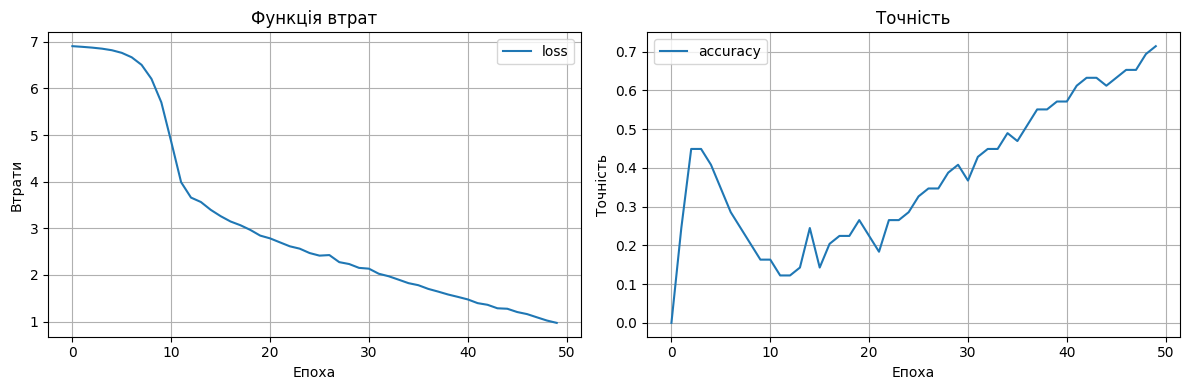

In [8]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="loss")
plt.xlabel("Епоха")
plt.ylabel("Втрати")
plt.title("Функція втрат")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="accuracy")
plt.xlabel("Епоха")
plt.ylabel("Точність")
plt.title("Точність")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

**Короткий аналіз:** loss поступово падав з приблизно 6.9 на першій епосі до близько 1.0 на останній, а accuracy зростала від 0 до близько 0.7. Криві ще йдуть униз і вгору, тобто модель могла б вчитися й далі. Цих графіків недостатньо, щоб оцінити якість моделі на новому тексті: вони показують точність тільки на тих самих даних, на яких модель вчилась, окремої перевірочної вибірки немає. Тому не видно, чи модель щось узагальнила, чи просто запам'ятала вірш.

### 9. Генерація нового тексту
Реалізуйте функцію **`buildPhrase(texts, str_len=20)`**, яка:
1. Перетворює початковий текст на індекси слів за допомогою `tokenizer`;
2. На кожному кроці передає моделі **останні `inp_words` індексів**;
3. Отримує прогноз `model.predict()`, визначає індекс найбільш імовірного слова через `argmax`;
4. Додає нове слово до послідовності, використовуючи `tokenizer.index_word`;
5. Повертає згенеровану фразу.

Перевірте роботу функції на початковій фразі **`"Думи мої думи"`**, згенеруйте **20 слів**.

**Зверніть увагу:** початкова фраза має містити щонайменше три відомі токенізатору слова. Якщо слово не знайдено, передбачте зрозумілу обробку цього випадку.

In [9]:
def buildPhrase(texts, str_len=20, model=model):
    # початкова фраза в індекси слів (невідомі слова пропускаються)
    res = tokenizer.texts_to_sequences([texts])[0]
    known = [tokenizer.index_word[i] for i in res]
    print("Відомі слова з початкової фрази:", known)

    # потрібно мінімум inp_words відомих слів
    if len(res) < inp_words:
        return "Потрібно хоча б " + str(inp_words) + " слова, які є в словнику"

    for _ in range(str_len):
        # беремо останні 3 слова і передбачаємо наступне
        x = np.array(res[-inp_words:]).reshape(1, inp_words)
        pred = model.predict(x, verbose=0)
        res.append(int(np.argmax(pred)))

    return " ".join(tokenizer.index_word.get(i, "?") for i in res)


print(buildPhrase("Думи мої думи", str_len=20))

Відомі слова з початкової фрази: ['думи', 'мої', 'думи']
думи мої думи мої лихо мої лихо на лихо на на на породило породило як чом чом вас не не розвіяв в в


## Частина 2. Автоматичний підбір гіперпараметрів (Keras Tuner)

### 10. Встановлення та імпорт Keras Tuner
У Google Colab або Jupyter Notebook встановіть (за потреби) пакет `keras-tuner`. Імпортуйте його під псевдонімом `kt`.

**Підказка:** для встановлення пакета в ноутбуці використовуйте `%pip install keras-tuner`.

Повторно створювати `X` та `Y` не потрібно: використайте вибірку з Частини 1.

In [10]:
%pip install -q keras-tuner

import keras_tuner as kt
print("Keras Tuner:", kt.__version__)

Keras Tuner: 1.4.8


### 11. Створення функції `build_model(hp)`
Опишіть функцію, яка будує та компілює модель і дає змогу змінювати гіперпараметри:

| Гіперпараметр | Простір пошуку |
|---|---|
| `embedding_dim` | від 128 до 512, крок 64 |
| `rnn_units` | від 64 до 256, крок 64 |
| `lstm_units` | від 64 до 256, крок 64 |
| `dropout_rate` | від 0.1 до 0.5, крок 0.1 |
| `dense_units` | від 64 до 256, крок 64 |
| `optimizer` | `adam` або `rmsprop` |

Збережіть структуру шарів із Частини 1: `Embedding → SimpleRNN → LSTM → Dropout → Dense → Dense`.

**Підказка:** використовуйте `hp.Int()`, `hp.Float()` і `hp.Choice()`; останній шар має `maxWordsCount` нейронів із `softmax`. Функція `build_model(hp)` повинна повертати скомпільовану модель.

In [11]:
def build_model(hp):
    model = Sequential([
        Embedding(maxWordsCount, hp.Int("embedding_dim", 128, 512, step=64), input_length=inp_words),
        SimpleRNN(hp.Int("rnn_units", 64, 256, step=64), activation='tanh', return_sequences=True),
        LSTM(hp.Int("lstm_units", 64, 256, step=64), activation='tanh'),
        Dropout(hp.Float("dropout_rate", 0.1, 0.5, step=0.1)),
        Dense(hp.Int("dense_units", 64, 256, step=64), activation='relu'),
        Dense(maxWordsCount, activation='softmax'),
    ])
    model.compile(
        optimizer=hp.Choice("optimizer", ["adam", "rmsprop"]),
        loss='categorical_crossentropy',
        metrics=['accuracy'],
    )
    return model

### 12. Пошук найкращих параметрів
Створіть `kt.RandomSearch` із такими налаштуваннями, як у вихідному прикладі:
- `hypermodel=build_model` (або передайте `build_model` першим аргументом);
- `objective='accuracy'`;
- `max_trials=10`;
- `executions_per_trial=1`;
- `directory='my_tuning'`, `project_name='text_prediction'`.

Запустіть `tuner.search(X, Y, epochs=10, batch_size=32)`.

**Завдання:** отримайте найкращий набір параметрів через `get_best_hyperparameters(num_trials=1)` і виведіть значення всіх шести гіперпараметрів.

**Примітка:** у вихідному прикладі підбір здійснюється за *навчальною* точністю. Це навчальна демонстрація; для об’єктивнішого порівняння зазвичай використовують окрему валідаційну вибірку.

In [12]:
tuner = kt.RandomSearch(
    build_model,
    objective='accuracy',
    max_trials=10,
    executions_per_trial=1,
    directory='my_tuning',
    project_name='text_prediction',
    overwrite=True,
    seed=42,
)

tuner.search(X, Y, epochs=10, batch_size=32, verbose=0)

best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]
print()
print("Найкращі гіперпараметри:")
for name in ["embedding_dim", "rnn_units", "lstm_units", "dropout_rate", "dense_units", "optimizer"]:
    print("  ", name, "=", best_hps.get(name))


Найкращі гіперпараметри:
   embedding_dim = 384
   rnn_units = 64
   lstm_units = 128
   dropout_rate = 0.2
   dense_units = 256
   optimizer = adam


### 13. Навчання моделі з підібраними параметрами
Створіть нову модель із найкращими параметрами (`tuner.hypermodel.build(best_hps)`), збережіть її у змінній `best_model`.

Навчіть `best_model` на `X`, `Y` із `batch_size=32`, `epochs=50`. Історію збережіть у `best_history`.

Виведіть `best_model.summary()`, а також кінцеві значення `loss` і `accuracy`.

In [13]:
best_model = tuner.hypermodel.build(best_hps)

best_history = best_model.fit(X, Y, batch_size=32, epochs=50, verbose=0)

best_model.summary()
print("Кількість параметрів:", best_model.count_params())
print("Остання епоха: loss =", round(best_history.history["loss"][-1], 4),
      "| accuracy =", round(best_history.history["accuracy"][-1], 4))

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 3, 384)         │       384,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 3, 64)          │        28,736 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1000)           │       257,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,404,730 (9.17 MB)

 Trainable params: 801,576 (3.06 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,603,154 (6.12 MB)

Кількість параметрів: 801576
Остання епоха: loss = 0.657 | accuracy = 0.8776


### 14. Графіки та генерація тексту після підбору
1. Побудуйте графіки `loss` і `accuracy` для `best_history`.
2. Порівняйте фінальні навчальні показники `model` та `best_model` в одному невеликому виводі або таблиці.
3. Згенеруйте **20 слів** із початкової фрази **`"Думи мої думи"`** за допомогою `best_model` (адаптуйте створену функцію або передайте модель їй як аргумент).
4. Порівняйте два згенеровані тексти.

**Зверніть увагу:** на такому невеликому тексті результати можуть бути нестабільними, а висока навчальна точність не означає якісної генерації нових фраз.

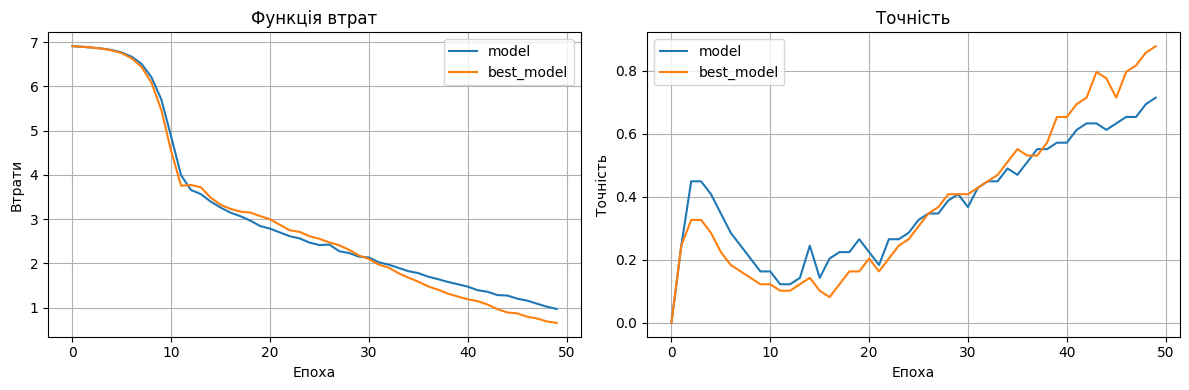

Модель             | loss    | accuracy | параметрів
model (початкова)  | 0.972 | 0.7143   | 632008
best_model (Tuner) | 0.657 | 0.8776   | 801576

Текст початкової моделі:
Відомі слова з початкової фрази: ['думи', 'мої', 'думи']
думи мої думи мої лихо мої лихо на лихо на на на породило породило як чом чом вас не не розвіяв в в

Текст після підбору параметрів:
Відомі слова з початкової фрази: ['думи', 'мої', 'думи']
думи мої думи мої лихо мені з вами нащо стали на папері сумними рядами чом вас вітер не розвіяв в степу як чом


In [14]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="model")
plt.plot(best_history.history["loss"], label="best_model")
plt.xlabel("Епоха")
plt.ylabel("Втрати")
plt.title("Функція втрат")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="model")
plt.plot(best_history.history["accuracy"], label="best_model")
plt.xlabel("Епоха")
plt.ylabel("Точність")
plt.title("Точність")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# порівняння фінальних навчальних показників
print("Модель             | loss    | accuracy | параметрів")
print("model (початкова)  |", round(history.history["loss"][-1], 4), "|", round(history.history["accuracy"][-1], 4),
      "  |", model.count_params())
print("best_model (Tuner) |", round(best_history.history["loss"][-1], 4), "|", round(best_history.history["accuracy"][-1], 4),
      "  |", best_model.count_params())

# генерація тексту двома моделями
print()
print("Текст початкової моделі:")
print(buildPhrase("Думи мої думи", str_len=20, model=model))
print()
print("Текст після підбору параметрів:")
print(buildPhrase("Думи мої думи", str_len=20, model=best_model))

## Висновки
Напишіть власний висновок **5–8 речень**, спираючись на отримані результати. Висвітліть:

1. Яку роль виконують шари `Embedding`, `SimpleRNN`, `LSTM` та `Dropout`?
2. Яких значень `loss` і `accuracy` досягла початкова модель?
3. Які гіперпараметри обрав Keras Tuner?
4. Чи покращилися навчальні показники після підбору параметрів?
5. Наскільки зв’язним був згенерований текст і чому обсяг корпусу важливий?

**Висновок студента:**

Шар `Embedding` перетворює кожне слово на числовий вектор, `SimpleRNN` і `LSTM` читають послідовність із трьох слів і враховують їх порядок (LSTM краще пам'ятає попередні слова), а `Dropout` вимикає частину нейронів під час навчання, щоб модель менше перенавчалась. Початкова модель (близько 632 тис. параметрів) після 50 епох досягла loss близько 0.97 і accuracy близько 0.71. Keras Tuner підібрав такі параметри: embedding_dim = 384, rnn_units = 64, lstm_units = 128, dropout_rate = 0.2, dense_units = 256, optimizer = adam. Після підбору навчальні показники покращились: loss впав до близько 0.66, а accuracy зросла до близько 0.88. Але підбір ішов за навчальною точністю, тому це ще не означає, що модель краща на новому тексті. Текст початкової моделі майже не має сенсу і повторює слова ("мої лихо мої лихо на лихо на на на"), а текст після підбору майже дослівно відтворює рядки вірша, тобто це запам'ятовування, а не нова творчість. Корпус дуже малий (52 слова, з них 35 унікальних, і лише 49 навчальних прикладів), тому модель не може вивчити мову, а для нормальної генерації тексту потрібен набагато більший обсяг даних.

---

### Що потрібно здати
Заповнений файл `.ipynb` з усім власним кодом, результатами виконання, графіками, двома прикладами згенерованого тексту, знайденими гіперпараметрами та висновками.